# 02 · Labels and candidates

Partitions: TRAIN (labels, R/K choice) and STUDENT_TEST (check only). Code: `pathsnap.labels`, `pathsnap.candidates`, `scripts/build_labels.py`, `scripts/candidate_sweep.py`, `scripts/build_candidates.py`, `scripts/eval_baseline.py`.

**The labels are derived.** The `.route` is an ordered arc list, not one label per GPS point. We align points to it ourselves, so labels inherit that uncertainty.

In [1]:
import subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, IFrame, display
from pathsnap.config import repo_path
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
RES, FIG = repo_path("experiments/results"), repo_path("experiments/figures")

def run(script, *args):
    """Run a repo script exactly as from the command line (outputs land in experiments/)."""
    out = subprocess.run([sys.executable, str(repo_path(script)), *args], capture_output=True, text=True, check=True)
    print(out.stdout[-3000:])

## 1. Monotonic alignment on one trip
State = route position; cost = distance to the route arc (capped at 100 m) + a heading term; the route index never decreases; skipping route arcs costs 10 m each, except across gaps over 30 s.

In [2]:
from pathsnap.io import discover_trips, load_trip
from pathsnap.geo import TripGeometry
from pathsnap.labels import AlignParams, align_route_to_observations
trip = load_trip(discover_trips("train")["00000072"], with_route=True)
geom = TripGeometry.from_trip(trip)
al = align_route_to_observations(geom, trip.route, AlignParams())
print(AlignParams())
al.describe().round(2)

AlignParams(skip_penalty_m=10.0, edge_skip_penalty_m=0.5, gap_s=30.0, cap_m=100.0, outlier_m=50.0, heading_weight_m=10.0, heading_min_move_m=5.0)


,obs_idx,route_pos,arc_id,dist_m
count,969.00,969.00,969.00,969.00
mean,484.00,75.53,2025.15,6.39
std,279.87,45.14,1992.73,4.36
min,0.00,0.00,3.00,0.01
25%,242.00,22.00,344.00,2.96
50%,484.00,85.00,933.00,5.74
75%,726.00,120.00,3507.00,8.93
max,968.00,130.00,6785.00,37.61


## 2. Label quality, all trips

Aligned 90 trips in 1.7 s with AlignParams(skip_penalty_m=10.0, edge_skip_penalty_m=0.5, gap_s=30.0, cap_m=100.0, outlier_m=50.0, heading_weight_m=10.0, heading_min_move_m=5.0)
[student_test] obs-weighted: >50 m 0.141%, >100 m 0.089%; median of trip medians 4.9 m; route coverage median 0.989 min 0.905
[train] obs-weighted: >50 m 11.115%, >100 m 9.862%; median of trip medians 4.7 m; route coverage median 0.990 min 0.809
partition  trip_id  n_obs  route_len  dist_median_m  dist_p95_m  dist_max_m  frac_gt_50m  frac_gt_100m  route_coverage  first_route_pos  last_route_pos  n_outliers  seconds
    train 00000054  19313        422     140.189285  212.354401  259.347046     0.888987      0.852638        0.988152                0             421       17169 0.837031
    train 00000033   5844        169     122.413242  142.058656  160.461502     0.590349      0.509582        0.958580                0             164        3450 0.199775
    train 00000002   7243        262       5.771540  242.3

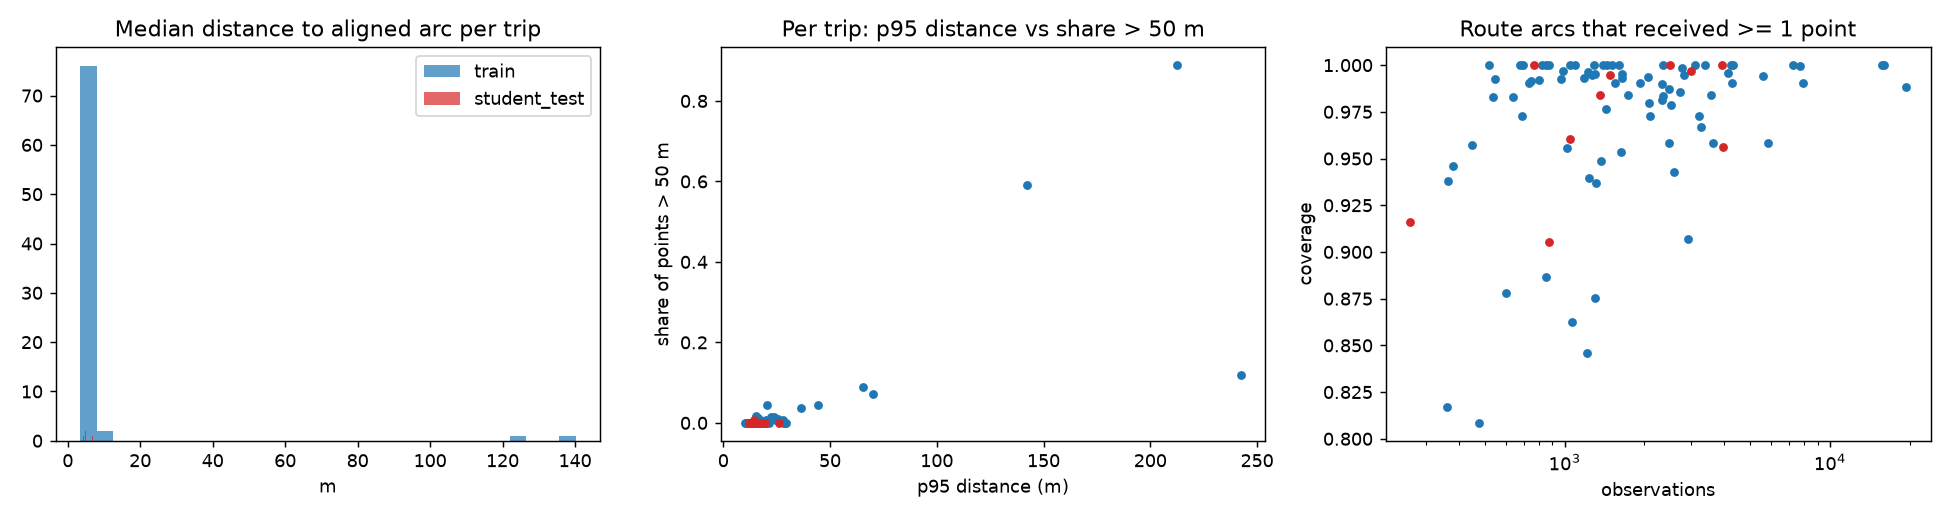

,partition,trip_id,n_obs,route_len,dist_median_m,dist_p95_m,dist_max_m,frac_gt_50m,frac_gt_100m,route_coverage,first_route_pos,last_route_pos,n_outliers,seconds
54,train,00000054,19313,422,140.189285,212.354401,259.347046,0.888987,0.852638,0.988152,0,421,17169,0.837031
36,train,00000033,5844,169,122.413242,142.058656,160.461502,0.590349,0.509582,0.958580,0,164,3450,0.199775
11,train,00000002,7243,262,5.771540,242.357303,569.657715,0.119840,0.099268,1.000000,0,261,868,0.218829
63,train,00000066,4325,365,6.590083,65.532869,647.181274,0.090173,0.045780,1.000000,0,364,390,0.187851
45,train,00000043,2322,427,11.048940,70.221282,402.145905,0.071921,0.025840,0.981265,0,424,167,0.115747
74,train,00000081,3224,778,4.601053,44.555626,166.411606,0.044355,0.019541,0.973008,0,777,143,0.136484


In [3]:
run("scripts/build_labels.py")
q = pd.read_csv(RES / "label_quality.csv", dtype={"trip_id": str})
display(Image(FIG / "label_quality.png"))
q.sort_values("frac_gt_50m", ascending=False).head(6)

Points more than 50 m from their aligned arc are flagged `is_outlier`. Most are in trips where the reference route covers only part of the GPS track, so those labels are unreliable and are left out of training and evaluation. Check maps (points coloured by aligned arc, outliers black):

In [4]:
run("scripts/make_maps.py", "--labels")
IFrame(src="../maps/labels_train_00000054.html", width=950, height=520)

/home/pqtl/ML-Hackathon-148-2026/maps/labels_train_00000072.html  (0.8 MB)
/home/pqtl/ML-Hackathon-148-2026/maps/labels_train_00000024.html  (0.8 MB)
/home/pqtl/ML-Hackathon-148-2026/maps/labels_train_00000078.html  (2.8 MB)
/home/pqtl/ML-Hackathon-148-2026/maps/labels_train_00000002.html  (2.8 MB)
/home/pqtl/ML-Hackathon-148-2026/maps/labels_train_00000054.html  (4.0 MB)
/home/pqtl/ML-Hackathon-148-2026/maps/labels_train_00000033.html  (4.5 MB)
/home/pqtl/ML-Hackathon-148-2026/maps/labels_student_test_00000056.html  (3.3 MB)



## 3. Candidate radius R and cap K (TRAIN only)

Sweep over 80 train trips in 1.4 s
max_candidates      5       10      15      20      30
radius_m                                              
15              0.0840  0.0745  0.0738  0.0733  0.0731
25              0.0396  0.0260  0.0245  0.0239  0.0235
40              0.0254  0.0098  0.0077  0.0064  0.0059
60              0.0233  0.0073  0.0051  0.0029  0.0003
80              0.0233  0.0073  0.0051  0.0029  0.0003
120             0.0233  0.0073  0.0051  0.0029  0.0003
200             0.0233  0.0073  0.0051  0.0029  0.0003
max_candidates    5     10     15     20     30
radius_m                                       
15              2.69  3.05   3.11   3.13   3.14
25              3.42  4.40   4.69   4.78   4.85
40              3.96  5.83   6.71   7.17   7.50
60              4.30  6.97   8.66   9.79  11.07
80              4.48  7.66   9.98  11.72  14.07
120             4.67  8.43  11.52  14.16  18.34
200             4.83  9.12  12.96  16.48  22.77
max_candidates      5       10      15

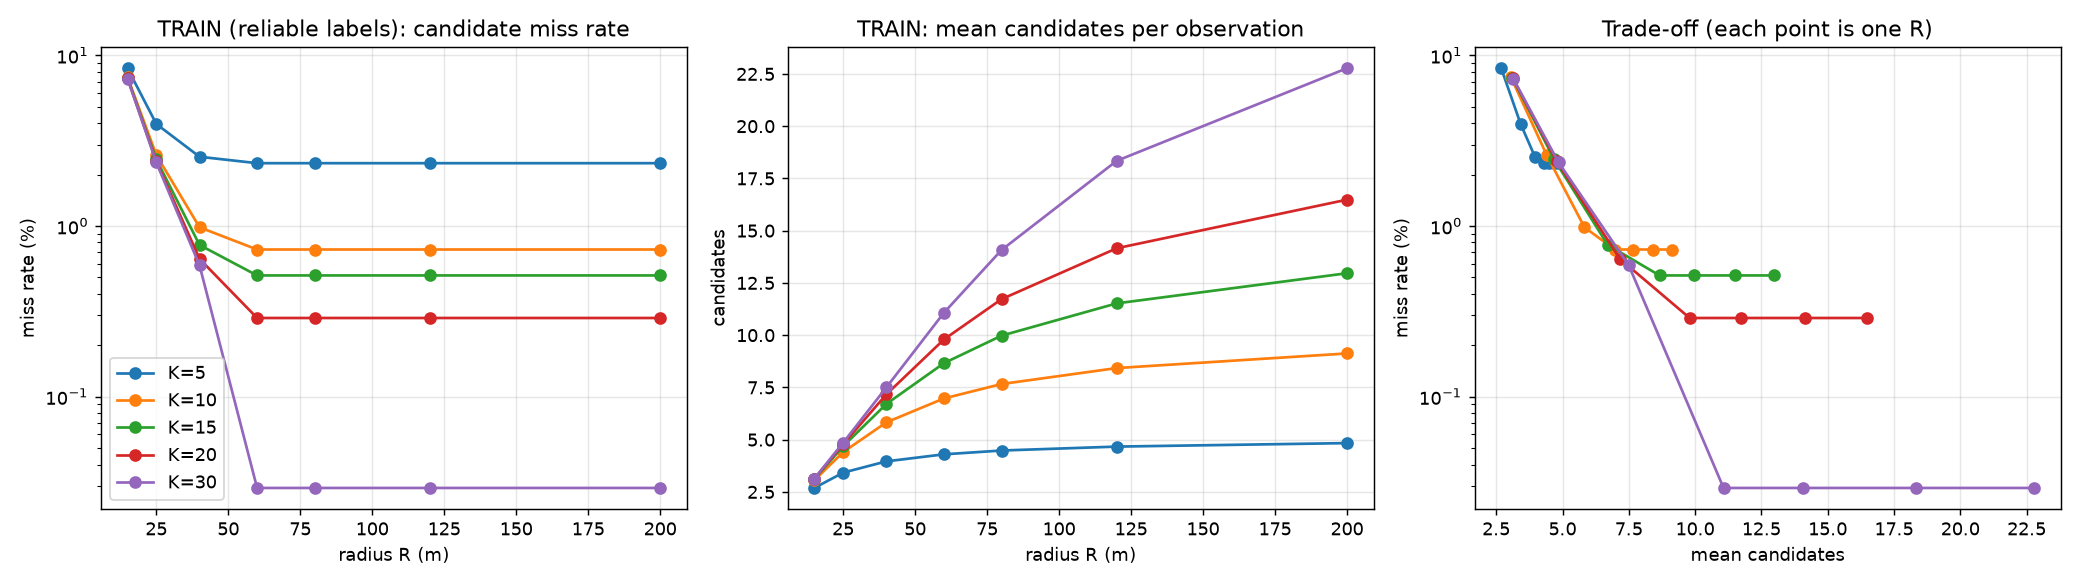

max_candidates,5,10,15,20,30
radius_m,,,,,
15,8.399,7.451,7.380,7.329,7.310
25,3.958,2.603,2.454,2.390,2.354
40,2.544,0.982,0.774,0.641,0.588
60,2.332,0.728,0.513,0.289,0.029
80,2.332,0.728,0.513,0.289,0.029
120,2.332,0.728,0.513,0.289,0.029
200,2.332,0.728,0.513,0.289,0.029


In [5]:
run("scripts/candidate_sweep.py")
display(Image(FIG / "candidate_miss_rate.png"))
m = pd.read_csv(RES / "candidate_miss_rate.csv")
rel = m[m.subset == "reliable"]
(rel.pivot(index="radius_m", columns="max_candidates", values="miss_rate") * 100).round(3)

In [6]:
rel.pivot(index="radius_m", columns="max_candidates", values="mean_cands").round(2)

max_candidates,5,10,15,20,30
radius_m,,,,,
15,2.69,3.05,3.11,3.13,3.14
25,3.42,4.40,4.69,4.78,4.85
40,3.96,5.83,6.71,7.17,7.50
60,4.30,6.97,8.66,9.79,11.07
80,4.48,7.66,9.98,11.72,14.07
120,4.67,8.43,11.52,14.16,18.34
200,4.83,9.12,12.96,16.48,22.77


Chosen: **R = 60 m, K = 30, fallback 150 m** (`configs/candidates.yaml`). The miss rate stops falling at R = 60 m; going from K = 20 to 30 cuts it tenfold for about one extra candidate per point.

In [7]:
run("scripts/build_candidates.py")
st = pd.read_csv(RES / "candidate_stats.csv", dtype={"trip_id": str})
st.groupby("partition")[["n_obs", "n_rows", "n_no_candidates", "n_fallback_used"]].sum()

Built 90 trips in 1.0 s with {'radius_m': 60, 'max_candidates': 30, 'fallback_radius_m': 150}
[student_test] rows 244,176  obs 19,160  mean cands 12.74  miss 0.1305%  miss(reliable) 0.0000%  no-cand obs 0  fallback obs 0  size 2.7 MB
[train] rows 2,449,078  obs 208,417  mean cands 11.75  miss 6.4601%  miss(reliable) 0.0291%  no-cand obs 198  fallback obs 17294  size 26.6 MB



,n_obs,n_rows,n_no_candidates,n_fallback_used
partition,,,,
student_test,19160,244176,0,0
train,208417,2449078,198,17294


In [8]:
c = pd.read_parquet(repo_path("data/processed/candidates/train/00000072.parquet"))
print(c.dtypes.to_dict())
c.head(8)  # note the reverse twins: identical dist_m, mirrored proj_frac

{'trip_id': <StringDtype(na_value=<NA>)>, 'obs_idx': dtype('int32'), 'arc_id': dtype('int32'), 'dist_m': dtype('float32'), 'proj_frac': dtype('float32'), 'label': dtype('int8')}


,trip_id,obs_idx,arc_id,dist_m,proj_frac,label
0,00000072,0,6091,15.636964,0.482827,1
1,00000072,0,6096,15.636964,0.517173,0
2,00000072,0,6090,38.619839,-0.853389,0
3,00000072,0,6093,38.619839,1.853389,0
4,00000072,0,6094,40.929268,1.593977,0
5,00000072,0,6097,40.929268,-0.593977,0
6,00000072,1,6091,13.921914,0.622626,1
7,00000072,1,6096,13.921914,0.377374,0


## 4. Why direction matters: a rule-based baseline
Nearest arc versus nearest arc with a heading penalty. The weight was chosen on TRAIN.

In [9]:
run("scripts/eval_baseline.py")
pd.read_csv(RES / "baseline_heading_sweep.csv").pivot(index="heading_weight_m", columns="partition", values="top1").round(4)

partition         student_test   train
heading_weight_m                      
0                       0.5296  0.5475
2                       0.8133  0.7973
5                       0.8211  0.8077
10                      0.8324  0.8193
20                      0.8324  0.8220
40                      0.8270  0.8134
best heading weight on TRAIN: 20 m (pipeline default 20 m)
 trip_id  n_obs  top1  route_continuity  total_ms
00000000   2503 0.938             0.651     23.48
00000007   1354 0.900             0.968     10.27
00000009   1049 0.815             0.704     22.32
00000040   2995 0.899             0.809     26.64
00000052    262 0.924             0.818      5.67
00000056   3931 0.860             0.691     38.57
00000065    768 0.842             0.676     18.77
00000076   1486 0.845             0.620     40.07
00000077   3911 0.662             0.718     29.65
00000091    874 0.796             0.629     14.16
student_test via predict_trip: Top-1 0.8324, continuity mean 0.728, total ms/tr

partition,student_test,train
heading_weight_m,,
0,0.5296,0.5475
2,0.8133,0.7973
5,0.8211,0.8077
10,0.8324,0.8193
20,0.8324,0.8220
40,0.8270,0.8134
